## När säljer vi?
*Finns det några tydliga tidsmönster under den observerade perioden (1 januari – 30 juni 2024)?*

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import sys  # tool to tell Python where to look for files

sys.path.append("..")

from src.time_analysis import add_time_columns, summarize_revenue
from src.time_charts import plot_bar

df = pd.read_csv("../data/ecommerce_sales.csv")
df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


In [15]:
# Clean column names

df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ", "_")
    .str.lower()
)

In [16]:
# Look at the structure

print("Rows and columns:", df.shape)
df.info()  # show column names, data types and non-empty counts

Rows and columns: (2500, 7)
<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   int64  
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 136.8 KB


In [17]:
# Check data quality

print("Missing values per column:")
print(df.isna().sum()) # count empty cells in each column

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate order_id:", df["order_id"].duplicated().sum()) # each order_id should appear only once

revenue_difference = (df["price"] * df["units"] - df["revenue"]).abs() # gap between price*units and revenue (always positive)
print("Max difference between price*units and revenue:", round(revenue_difference.max(), 2))

Missing values per column:
order_id    0
date        0
city        0
category    0
price       0
units       0
revenue     0
dtype: int64
Duplicate rows: 0
Duplicate order_id: 0
Max difference between price*units and revenue: 0.0


In [18]:
# Fix the date column and check missing dates

print("Before:", df["date"].dtype)

df["date"] = pd.to_datetime(df["date"]) # turn text into real dates
df = df.sort_values("date").reset_index(drop=True) # sort oldest to newest and restart row numbers at 0

print("After:", df["date"].dtype)
print("First date:", df["date"].min())
print("Last date:", df["date"].max())

expected_days = (df["date"].max() - df["date"].min()).days + 1  # days from first to last date
print("Days with sales:", df["date"].nunique(), "of", expected_days)

Before: str
After: datetime64[us]
First date: 2024-01-01 00:00:00
Last date: 2024-06-30 00:00:00
Days with sales: 182 of 182


In [19]:
df = add_time_columns(df)  # add month and weekday columns in one step
df[["date", "month_number", "month_name", "weekday_number", "weekday_name"]].head()

,date,month_number,month_name,weekday_number,weekday_name
0,2024-01-01,1,January,1,Monday
1,2024-01-01,1,January,1,Monday
2,2024-01-01,1,January,1,Monday
3,2024-01-01,1,January,1,Monday
4,2024-01-01,1,January,1,Monday


In [20]:
# Sales by month

monthly_summary = summarize_revenue(df, ["month_number", "month_name"])
monthly_summary.drop(columns="month_number")  # show without month number

,month_name,total_revenue,total_units,order_count,average_order_value
0,January,664083.32,1353,445,1492.32
1,February,548462.03,1097,357,1536.31
2,March,487602.00,1116,411,1186.38
3,April,580194.83,1305,432,1343.04
4,May,632165.16,1367,433,1459.97
5,June,590259.89,1225,422,1398.72


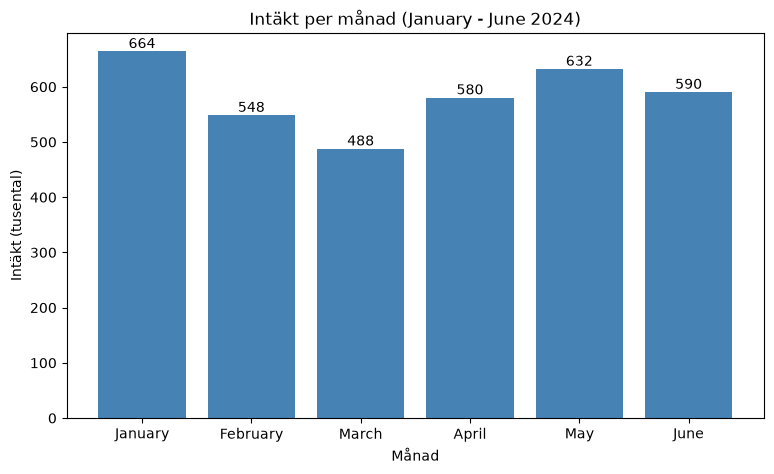

In [21]:
# Chart 1: Bar chart - revenue for each month (which month sells most?)

revenue_in_thousands = monthly_summary["total_revenue"] / 1000  # show revenue in thousands

fig = plot_bar(
    monthly_summary["month_name"],  # bar names
    revenue_in_thousands,  # bar heights
    "Intäkt per månad (January - June 2024)",
    "Månad",
    "Intäkt (tusental)"
)
plt.show()

Diagrammet visar den totala intäkten för varje månad. Januari är högst (ca 664 000) och mars är lägst (ca 488 000).

In [22]:
# Sales by weekday

weekday_summary = summarize_revenue(df, ["weekday_number", "weekday_name"])
weekday_summary.drop(columns="weekday_number")  # show without weekday number

,weekday_name,total_revenue,total_units,order_count,average_order_value
0,Monday,527263.73,1115,368,1432.78
1,Tuesday,512978.35,1037,354,1449.09
2,Wednesday,502661.61,1063,346,1452.78
3,Thursday,518871.71,1098,361,1437.32
4,Friday,501396.53,1082,357,1404.47
5,Saturday,481483.77,1052,355,1356.29
6,Sunday,458111.53,1016,359,1276.08


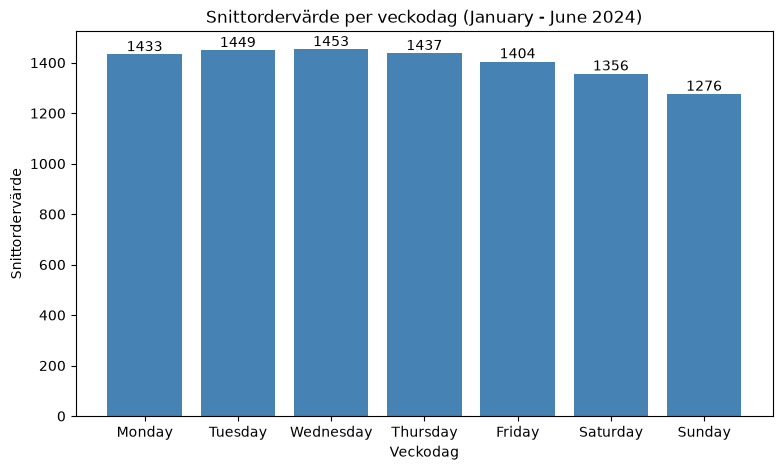

In [23]:
# Chart 2: Bar chart - average order value for each weekday (which day do customers spend least per order?)

fig = plot_bar(
    weekday_summary["weekday_name"],  # bar names
    weekday_summary["average_order_value"],  # bar heights
    "Snittordervärde per veckodag (January - June 2024)",
    "Veckodag",
    "Snittordervärde"
)
plt.show()

Diagrammet visar snittordervärdet för varje veckodag. Söndag är lägst (ca 1 276), ca 12 % under måndag–torsdag, trots att antalet ordrar är ungefär lika många.

In [24]:
# Sales by week

weekly_summary = summarize_revenue(df, ["week_number"])  # group by week number

week_dates = (
    df.groupby("week_number")
    .agg(
        first_day = ("date", "min"),  # first date of each week
        last_day = ("date", "max"),  # last date of each week
    )
    .reset_index()  # turn the group labels back into normal columns
)

weekly_summary["week_label"] = (
    week_dates["first_day"].dt.strftime("%d %b")
    + " - "
    + week_dates["last_day"].dt.strftime("%d %b")
)

print("Number of weeks:", len(weekly_summary))
weekly_summary[["week_label", "total_revenue", "total_units", "order_count", "average_order_value"]].head()

Number of weeks: 26


,week_label,total_revenue,total_units,order_count,average_order_value
0,01 Jan - 07 Jan,161119.04,326,108,1491.84
1,08 Jan - 14 Jan,136568.68,265,81,1686.03
2,15 Jan - 21 Jan,147225.11,319,104,1415.63
3,22 Jan - 28 Jan,165832.80,328,108,1535.49
4,29 Jan - 04 Feb,124154.34,247,89,1394.99


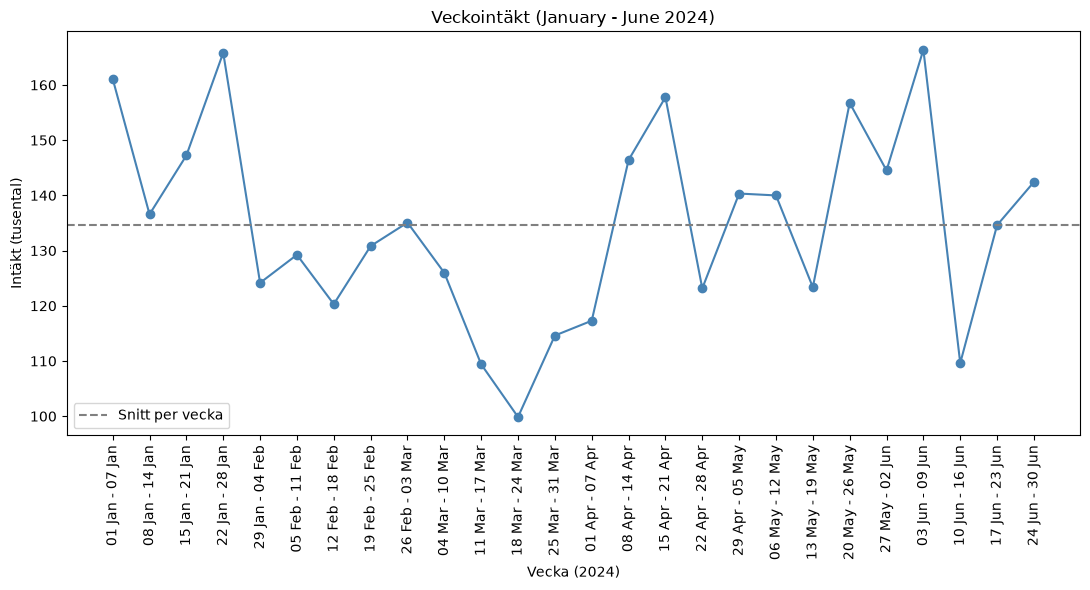

In [25]:
# Chart 3: Line chart - revenue for each week with the average line (which weeks are above or below normal?)

revenue_in_thousands = weekly_summary["total_revenue"] / 1000  # show revenue in thousands

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(weekly_summary["week_label"], revenue_in_thousands, color="steelblue", marker="o")  # one dot per week
ax.axhline(revenue_in_thousands.mean(), color="gray", linestyle="--", label="Snitt per vecka")  # dashed average line
ax.set_title("Veckointäkt (January - June 2024)")
ax.set_xlabel("Vecka (2024)")
ax.set_ylabel("Intäkt (tusental)")
ax.tick_params(axis="x", rotation=90)  # turn the labels so they do not overlap
ax.legend()  # show the label of the average line
fig.tight_layout()  # fit the long labels inside the picture

plt.show()

Diagrammet visar intäkten för varje vecka. Veckan 18–24 mars är lägst (ca 100 000), och intäkten ligger under veckosnittet fem veckor i rad (4 mars – 7 april).

In [26]:
# Mean and median of daily and weekly revenue

daily_summary = summarize_revenue(df, ["date"])

print("Intäkt per dag - snitt:", round(daily_summary["total_revenue"].mean()))  # average day
print("Intäkt per dag - median:", round(daily_summary["total_revenue"].median()))  # middle day
print("Intäkt per vecka - snitt::", round(weekly_summary["total_revenue"].mean()))
print("Intäkt per vecka - median:", round(weekly_summary["total_revenue"].median()))

Intäkt per dag - snitt: 19246
Intäkt per dag - median: 18865
Intäkt per vecka - snitt:: 134722
Intäkt per vecka - median: 134838


En vanlig dag säljer vi för ca 19 000 (median ca 18 900). Per vecka är både snittet och medianen ca 135 000. De flesta veckor ligger alltså nära varandra, och de svaga veckorna i mars syns tydligt.

## Sammanfattning: när säljer vi?

**Kort svar:** Året börjar starkt, mars tar paus och söndagen handlar smått.

- **Månad:** Januari är starkast (ca 664 000) och mars svagast (ca 488 000), drygt en fjärdedel lägre.
- **Varför mars?** Antalet ordrar är normalt (411), men snittordervärdet är lägst (ca 1 186 mot 1 340–1 540 andra månader). Kunderna handlar alltså för mindre per order. Antalet enheter per order är också lägst i mars (2,72 mot 2,90–3,16).
- **Vecka:** Snittet är ca 135 000 per vecka. Vecka 12 (18–24 mars) är lägst med ca 100 000, och vecka 10–14 (4 mars – 7 april) ligger under snittet.
- **Veckodag:** Måndag ger mest intäkt (ca 527 000) och söndag minst (ca 458 000). Snittordervärdet tenderar att vara lägre på söndagar, ca 12 % under måndag–torsdag, fast antalet ordrar är lika många.
- **Tips till ledningen:** Testa kampanjer som höjer ordervärdet i mars och på söndagar, till exempel paketerbjudanden eller fri frakt över en viss summa.
- **Försiktighet:** Vi har bara sex månader, så vi vet inte om mönstret beror på säsong eller om det är en engångsgrej.
